# 03 — Fusion Analysis
Analyze the feature-level fusion process.

This notebook:
- Demonstrates channel, spatial, and cross-modal attention
- Visualizes attention maps
- Compares fused features to individual modality features
- Shows how fusion weights evolve

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.backbone import DualStreamBackbone
from src.fusion import (
    ChannelAttention, SpatialAttention, CrossModalAttention,
    FeatureFusionBlock, MultiScaleFeatureFusion
)
from src.utils import create_sample_data, get_device
from src.dataset import MultiModalDataset

%matplotlib inline
device = get_device('auto')
print(f'Using device: {device}')

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


In [2]:
# Load data and extract backbone features
DATA_DIR = os.path.join('..', 'data', 'sample')
if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    create_sample_data(DATA_DIR, num_samples=10)

dataset = MultiModalDataset(
    root_dir=DATA_DIR,
    annotation_file=os.path.join(DATA_DIR, 'annotations.json'),
    img_size=(320, 320)  # smaller for faster processing
)

sample = dataset[0]
rgb_input = sample['rgb'].unsqueeze(0).to(device)
thermal_input = sample['thermal'].unsqueeze(0).to(device)

backbone = DualStreamBackbone('resnet34', pretrained=True).to(device)
backbone.eval()

with torch.no_grad():
    rgb_feats, thermal_feats = backbone(rgb_input, thermal_input)

print('Backbone features ready:')
for i, (r, t) in enumerate(zip(rgb_feats, thermal_feats)):
    print(f'  Level {i}: RGB {r.shape}, Thermal {t.shape}')

Backbone features ready:
  Level 0: RGB torch.Size([1, 64, 80, 80]), Thermal torch.Size([1, 64, 80, 80])
  Level 1: RGB torch.Size([1, 128, 40, 40]), Thermal torch.Size([1, 128, 40, 40])
  Level 2: RGB torch.Size([1, 256, 20, 20]), Thermal torch.Size([1, 256, 20, 20])
  Level 3: RGB torch.Size([1, 512, 10, 10]), Thermal torch.Size([1, 512, 10, 10])


## 1. Channel Attention Visualization

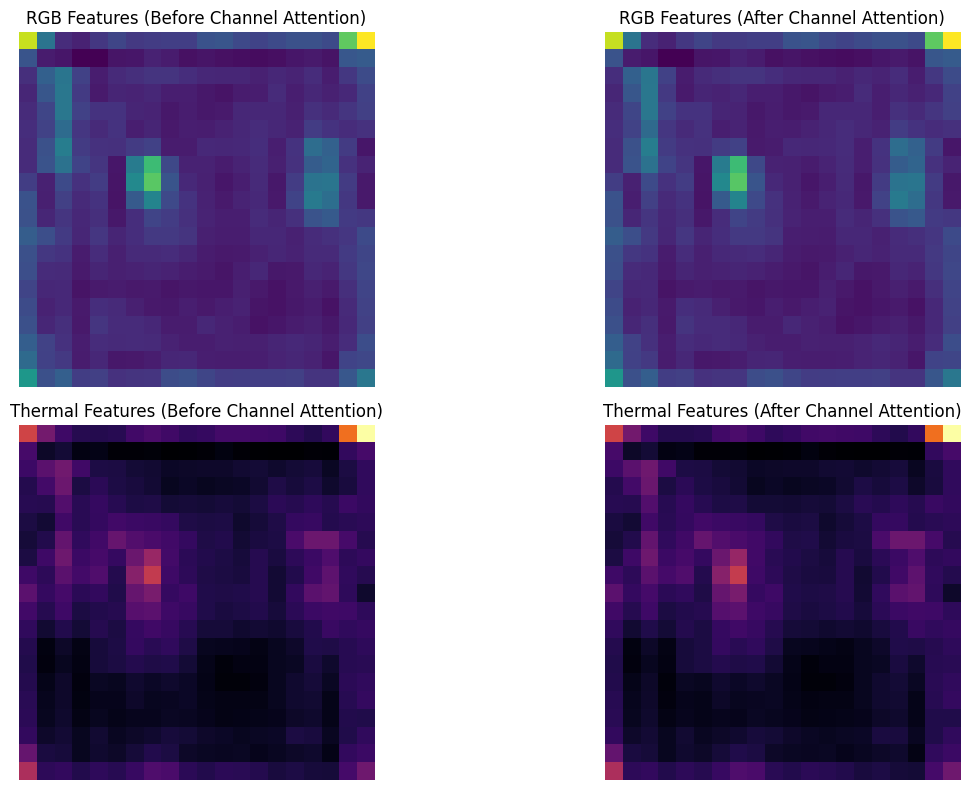

In [3]:
# Apply channel attention to Level 3 features
level = 2  # Level 3 (256 channels)
ch_attn = ChannelAttention(rgb_feats[level].shape[1]).to(device)
ch_attn.eval()

with torch.no_grad():
    rgb_attended = ch_attn(rgb_feats[level])
    thermal_attended = ch_attn(thermal_feats[level])

# Visualize attention weights
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Before vs after attention - RGB
rgb_mean_before = rgb_feats[level][0].mean(dim=0).cpu().numpy()
rgb_mean_after = rgb_attended[0].mean(dim=0).cpu().numpy()

axes[0, 0].imshow(rgb_mean_before, cmap='viridis')
axes[0, 0].set_title('RGB Features (Before Channel Attention)')
axes[0, 1].imshow(rgb_mean_after, cmap='viridis')
axes[0, 1].set_title('RGB Features (After Channel Attention)')

# Before vs after attention - Thermal
th_mean_before = thermal_feats[level][0].mean(dim=0).cpu().numpy()
th_mean_after = thermal_attended[0].mean(dim=0).cpu().numpy()

axes[1, 0].imshow(th_mean_before, cmap='inferno')
axes[1, 0].set_title('Thermal Features (Before Channel Attention)')
axes[1, 1].imshow(th_mean_after, cmap='inferno')
axes[1, 1].set_title('Thermal Features (After Channel Attention)')

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Spatial Attention Visualization

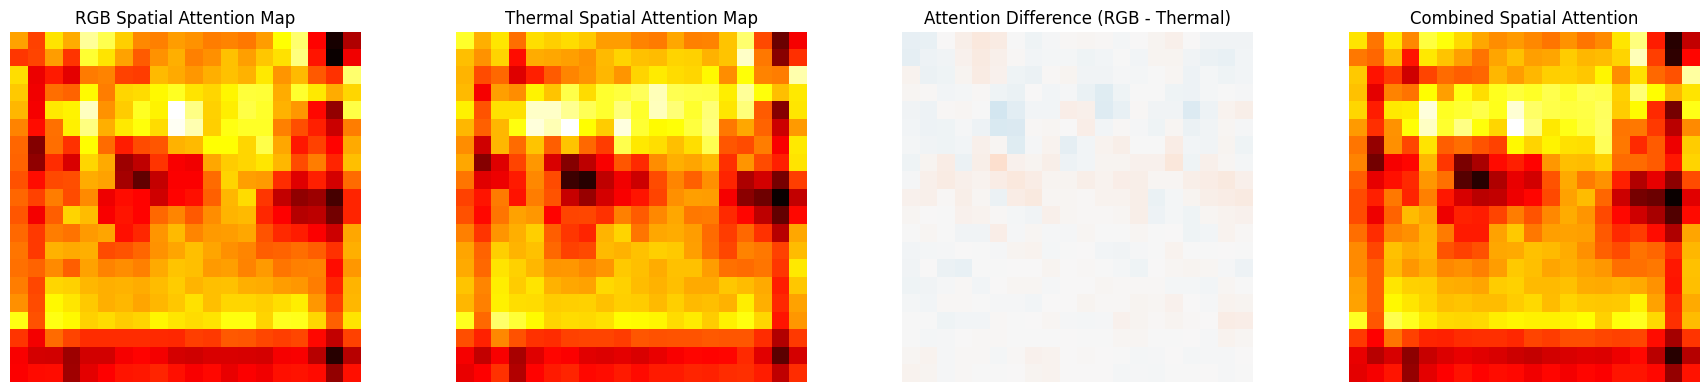

In [4]:
sp_attn = SpatialAttention().to(device)
sp_attn.eval()

with torch.no_grad():
    rgb_spatial = sp_attn(rgb_feats[level])
    thermal_spatial = sp_attn(thermal_feats[level])
    
    # Get spatial attention maps directly
    avg_pool_r = torch.mean(rgb_feats[level], dim=1, keepdim=True)
    max_pool_r = torch.max(rgb_feats[level], dim=1, keepdim=True)[0]
    spatial_map_r = sp_attn.conv(torch.cat([avg_pool_r, max_pool_r], dim=1))
    
    avg_pool_t = torch.mean(thermal_feats[level], dim=1, keepdim=True)
    max_pool_t = torch.max(thermal_feats[level], dim=1, keepdim=True)[0]
    spatial_map_t = sp_attn.conv(torch.cat([avg_pool_t, max_pool_t], dim=1))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(spatial_map_r[0, 0].cpu().numpy(), cmap='hot')
axes[0].set_title('RGB Spatial Attention Map')
axes[1].imshow(spatial_map_t[0, 0].cpu().numpy(), cmap='hot')
axes[1].set_title('Thermal Spatial Attention Map')

# Difference
diff = (spatial_map_r[0, 0] - spatial_map_t[0, 0]).cpu().numpy()
axes[2].imshow(diff, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[2].set_title('Attention Difference (RGB - Thermal)')

# Combined
combined = ((spatial_map_r[0, 0] + spatial_map_t[0, 0]) / 2).cpu().numpy()
axes[3].imshow(combined, cmap='hot')
axes[3].set_title('Combined Spatial Attention')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Full Feature Fusion

Fused feature shapes:
  Level 0: torch.Size([1, 64, 80, 80])
  Level 1: torch.Size([1, 128, 40, 40])
  Level 2: torch.Size([1, 256, 20, 20])
  Level 3: torch.Size([1, 512, 10, 10])


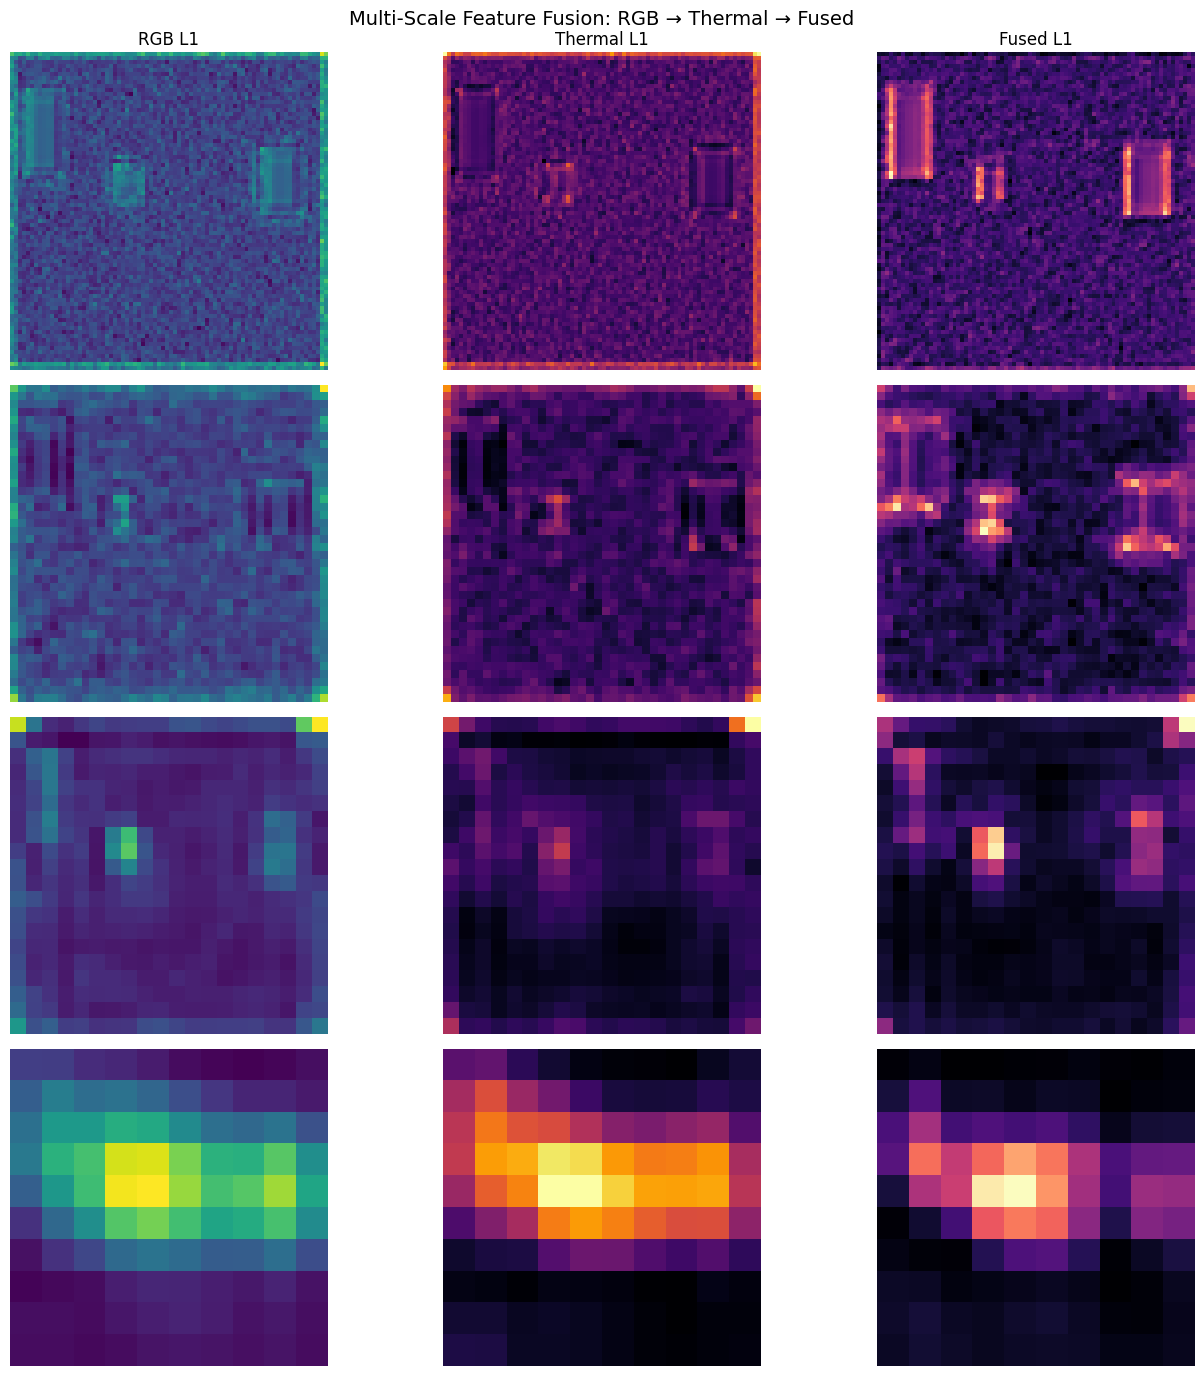

In [5]:
# Apply full multi-scale fusion
channel_list = [f.shape[1] for f in rgb_feats]
fusion_module = MultiScaleFeatureFusion(channel_list).to(device)
fusion_module.eval()

with torch.no_grad():
    fused_feats = fusion_module(rgb_feats, thermal_feats)

print('Fused feature shapes:')
for i, f in enumerate(fused_feats):
    print(f'  Level {i}: {f.shape}')

# Visualize fused vs individual
fig, axes = plt.subplots(4, 3, figsize=(14, 14))

for i in range(4):
    rgb_mean = rgb_feats[i][0].mean(dim=0).cpu().numpy()
    thermal_mean = thermal_feats[i][0].mean(dim=0).cpu().numpy()
    fused_mean = fused_feats[i][0].mean(dim=0).cpu().numpy()
    
    axes[i, 0].imshow(rgb_mean, cmap='viridis')
    axes[i, 0].set_title(f'RGB L{i+1}' if i == 0 else '')
    axes[i, 0].set_ylabel(f'Level {i+1}\n({rgb_feats[i].shape[2]}x{rgb_feats[i].shape[3]})')
    
    axes[i, 1].imshow(thermal_mean, cmap='inferno')
    axes[i, 1].set_title(f'Thermal L{i+1}' if i == 0 else '')
    
    axes[i, 2].imshow(fused_mean, cmap='magma')
    axes[i, 2].set_title(f'Fused L{i+1}' if i == 0 else '')
    
    for ax in axes[i]:
        ax.axis('off')

plt.suptitle('Multi-Scale Feature Fusion: RGB → Thermal → Fused', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Fusion Weight Analysis

Fusion weights (RGB vs Thermal importance per level):
  Level 1: RGB weight = 0.6225, Thermal weight = 0.6225
  Level 2: RGB weight = 0.6225, Thermal weight = 0.6225
  Level 3: RGB weight = 0.6225, Thermal weight = 0.6225
  Level 4: RGB weight = 0.6225, Thermal weight = 0.6225


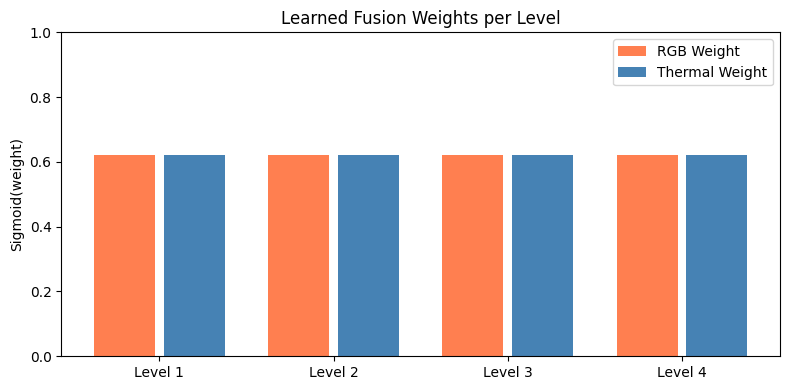

In [6]:
# Inspect learned fusion weights
print('Fusion weights (RGB vs Thermal importance per level):')
print('='*50)

weights_data = []
for i, block in enumerate(fusion_module.fusion_blocks):
    rgb_w = torch.sigmoid(block.rgb_weight).item()
    thermal_w = torch.sigmoid(block.thermal_weight).item()
    weights_data.append({'level': i+1, 'rgb': rgb_w, 'thermal': thermal_w})
    print(f'  Level {i+1}: RGB weight = {rgb_w:.4f}, Thermal weight = {thermal_w:.4f}')

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
levels = [d['level'] for d in weights_data]
rgb_ws = [d['rgb'] for d in weights_data]
thermal_ws = [d['thermal'] for d in weights_data]

x = np.arange(len(levels))
ax.bar(x - 0.2, rgb_ws, 0.35, label='RGB Weight', color='coral')
ax.bar(x + 0.2, thermal_ws, 0.35, label='Thermal Weight', color='steelblue')
ax.set_xticks(x)
ax.set_xticklabels([f'Level {l}' for l in levels])
ax.set_ylabel('Sigmoid(weight)')
ax.set_title('Learned Fusion Weights per Level')
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()